In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

In [2]:
DATA_PATH = Path("../Data/clean_data.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["279"].value_counts())

Dataset shape: (430, 262)

Target distribution:
279
0    245
1    185
Name: count, dtype: int64


In [3]:
TARGET_COLUMN = "279"

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (430, 261)
Target: (430,)


In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    )
}

models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "Linear SVC": LinearSVC(
        max_iter=10000, random_state=RANDOM_STATE
    ),
    "RBF SVC": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE
    )
}

def evaluate_pca_model(model, X, y):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    return {
        metric: scores[f"test_{metric}"].mean()
        for metric in scoring
    }

print("PCA evaluation pipeline ready!")

PCA evaluation pipeline ready!


In [5]:
pca_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    result = evaluate_pca_model(model, X, y)
    result["Model"] = name

    pca_results.append(result)

pca_results_df = pd.DataFrame(pca_results)

pca_results_df = pca_results_df[
    ["Model", "accuracy", "precision", "recall", "f1"]
]

print("\nPCA Model Comparison Results:")
display(pca_results_df.round(4))


Evaluating KNN...
Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Linear SVC...
Evaluating RBF SVC...
Evaluating Random Forest...

PCA Model Comparison Results:


,Model,accuracy,precision,recall,f1
0,KNN,0.6837,0.8353,0.3351,0.4696
1,Logistic Regression,0.7442,0.7393,0.6324,0.6798
2,Decision Tree,0.6767,0.6414,0.5838,0.6071
3,Linear SVC,0.7279,0.7152,0.6162,0.6604
4,RBF SVC,0.7674,0.8089,0.6054,0.6917
5,Random Forest,0.7512,0.7404,0.6541,0.6927


In [6]:
OUTPUT_PATH = Path("pca_results.csv")

pca_results_df.to_csv(OUTPUT_PATH, index=False)

print(f"PCA results saved to: {OUTPUT_PATH}")

PCA results saved to: pca_results.csv


In [7]:
baseline_path = Path("baseline_results.csv")

baseline_df = pd.read_csv(baseline_path)

baseline_df = baseline_df.rename(columns={
    "accuracy": "accuracy_without_pca",
    "precision": "precision_without_pca",
    "recall": "recall_without_pca",
    "f1": "f1_without_pca"
})

pca_comparison = baseline_df.merge(
    pca_results_df,
    on="Model",
    how="inner"
)

pca_comparison = pca_comparison.rename(columns={
    "accuracy": "accuracy_with_pca",
    "precision": "precision_with_pca",
    "recall": "recall_with_pca",
    "f1": "f1_with_pca"
})

display(pca_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score,accuracy_with_pca,precision_with_pca,recall_with_pca,f1_with_pca
0,KNN,0.6581,0.7910,0.2757,0.4025,0.6837,0.8353,0.3351,0.4696
1,Logistic Regression,0.7465,0.7228,0.6703,0.6946,0.7442,0.7393,0.6324,0.6798
2,Decision Tree,0.7512,0.7403,0.6757,0.7035,0.6767,0.6414,0.5838,0.6071
3,Linear SVC,0.6953,0.6531,0.6270,0.6396,0.7279,0.7152,0.6162,0.6604
4,RBF SVC,0.7674,0.7771,0.6486,0.7059,0.7674,0.8089,0.6054,0.6917
5,Random Forest,0.8442,0.8475,0.7838,0.8126,0.7512,0.7404,0.6541,0.6927


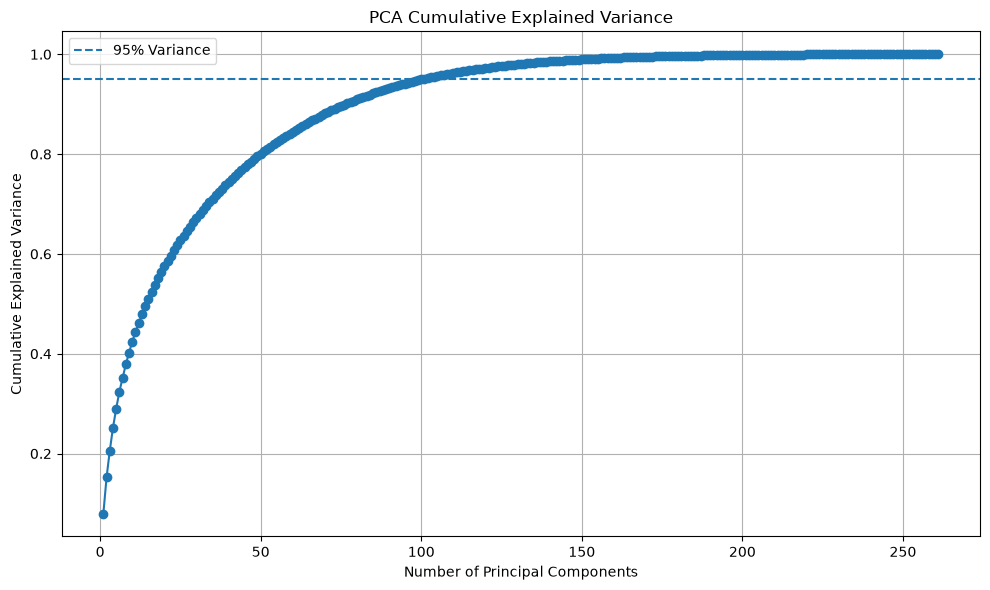

Components required to retain 95% variance: 101


In [8]:
pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA())
])

X_transformed = pca_pipeline.fit_transform(X)

pca_model = pca_pipeline.named_steps["pca"]

cumulative_variance = np.cumsum(
    pca_model.explained_variance_ratio_
)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("../Image/pca_explained_variance.png", dpi=300)
plt.show()

print(
    "Components required to retain 95% variance:",
    np.argmax(cumulative_variance >= 0.95) + 1
)

In [ ]:
metrics = ["accuracy", "precision", "recall", "f1"]

for metric in metrics:
    plt.figure(figsize=(12, 6))

    x = np.arange(len(pca_comparison["Model"]))
    width = 0.35

    plt.bar(
        x - width / 2,
        pca_comparison[f"{metric}_without_pca"],
        width,
        label="Without PCA"
    )

    plt.bar(
        x + width / 2,
        pca_comparison[f"{metric}_with_pca"],
        width,
        label="With PCA"
    )

    plt.xlabel("Models")
    plt.ylabel(metric.capitalize())
    plt.title(f"{metric.capitalize()}: With PCA vs Without PCA")
    plt.xticks(x, pca_comparison["Model"], rotation=30)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"../Image/pca_{metric}_comparison.png",
        dpi=300
    )

    plt.show()

In [10]:
print("Baseline columns:")
print(baseline_df.columns.tolist())

print("\nPCA columns:")
print(pca_results_df.columns.tolist())

print("\nComparison columns:")
print(pca_comparison.columns.tolist())

Baseline columns:
['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']

PCA columns:
['Model', 'accuracy', 'precision', 'recall', 'f1']

Comparison columns:
['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'accuracy_with_pca', 'precision_with_pca', 'recall_with_pca', 'f1_with_pca']


In [11]:
# Standardise baseline column names
baseline_df.columns = baseline_df.columns.str.strip().str.lower()

# Standardise PCA column names
pca_results_df.columns = pca_results_df.columns.str.strip().str.lower()

# Rename model column if needed
if "model" not in baseline_df.columns:
    baseline_df = baseline_df.rename(columns={"models": "model"})

# Rename metric columns
baseline_df = baseline_df.rename(columns={
    "accuracy": "accuracy_without_pca",
    "precision": "precision_without_pca",
    "recall": "recall_without_pca",
    "f1": "f1_without_pca"
})

pca_results_df = pca_results_df.rename(columns={
    "accuracy": "accuracy_with_pca",
    "precision": "precision_with_pca",
    "recall": "recall_with_pca",
    "f1": "f1_with_pca"
})

# Merge both results
pca_comparison = pd.merge(
    baseline_df,
    pca_results_df,
    on="model",
    how="inner"
)

display(pca_comparison.round(4))

,model,accuracy_without_pca,precision_without_pca,recall_without_pca,f1-score,accuracy_with_pca,precision_with_pca,recall_with_pca,f1_with_pca
0,KNN,0.6581,0.7910,0.2757,0.4025,0.6837,0.8353,0.3351,0.4696
1,Logistic Regression,0.7465,0.7228,0.6703,0.6946,0.7442,0.7393,0.6324,0.6798
2,Decision Tree,0.7512,0.7403,0.6757,0.7035,0.6767,0.6414,0.5838,0.6071
3,Linear SVC,0.6953,0.6531,0.6270,0.6396,0.7279,0.7152,0.6162,0.6604
4,RBF SVC,0.7674,0.7771,0.6486,0.7059,0.7674,0.8089,0.6054,0.6917
5,Random Forest,0.8442,0.8475,0.7838,0.8126,0.7512,0.7404,0.6541,0.6927


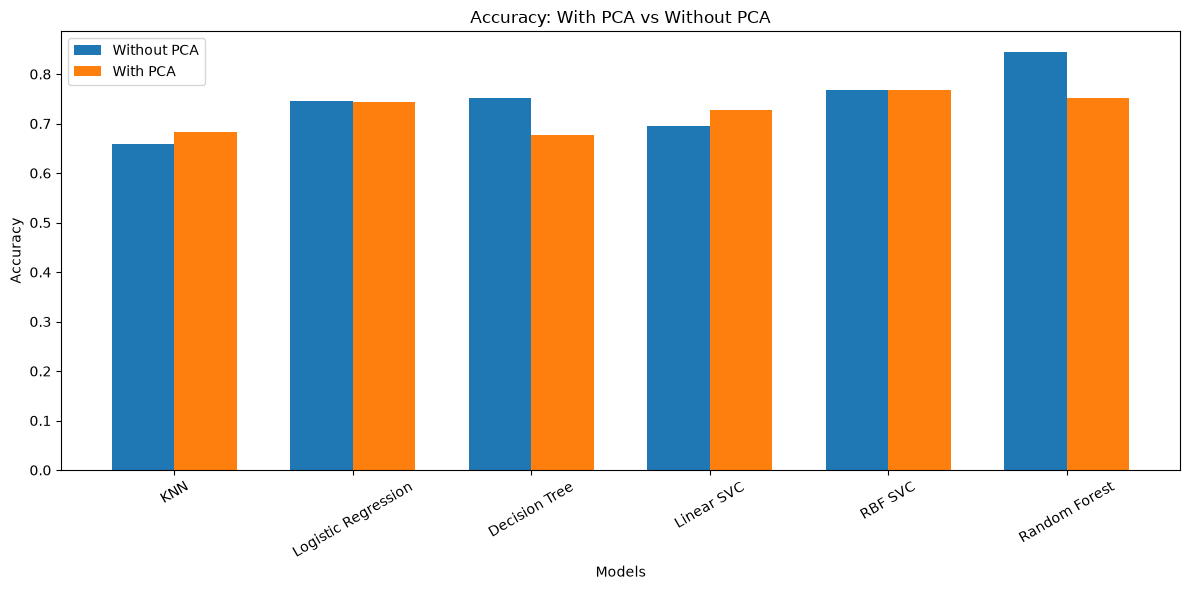

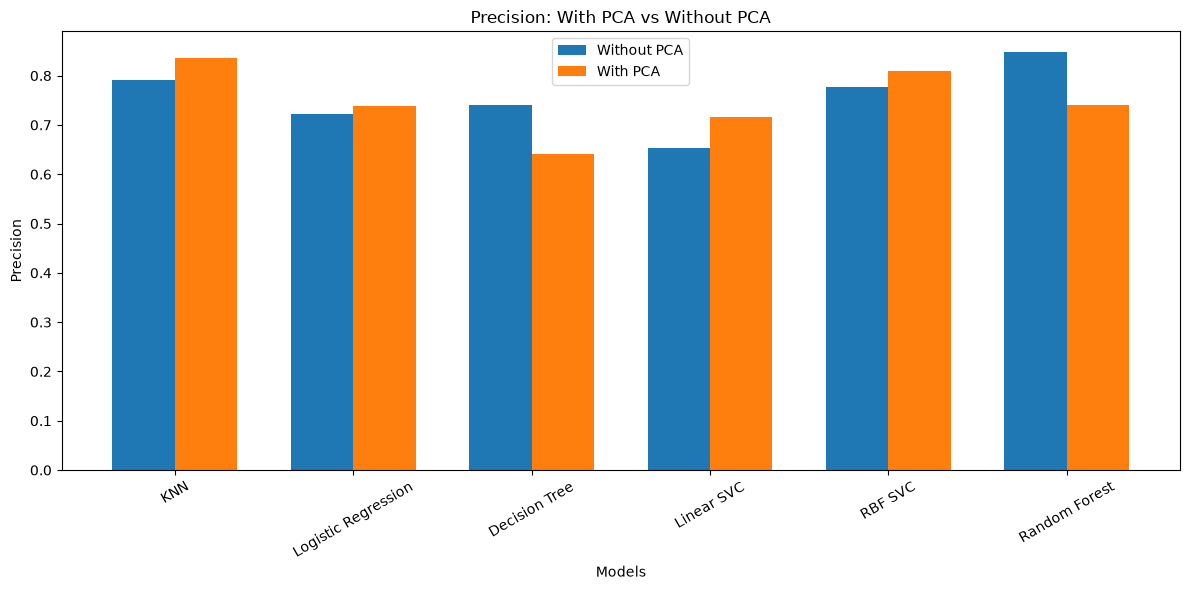

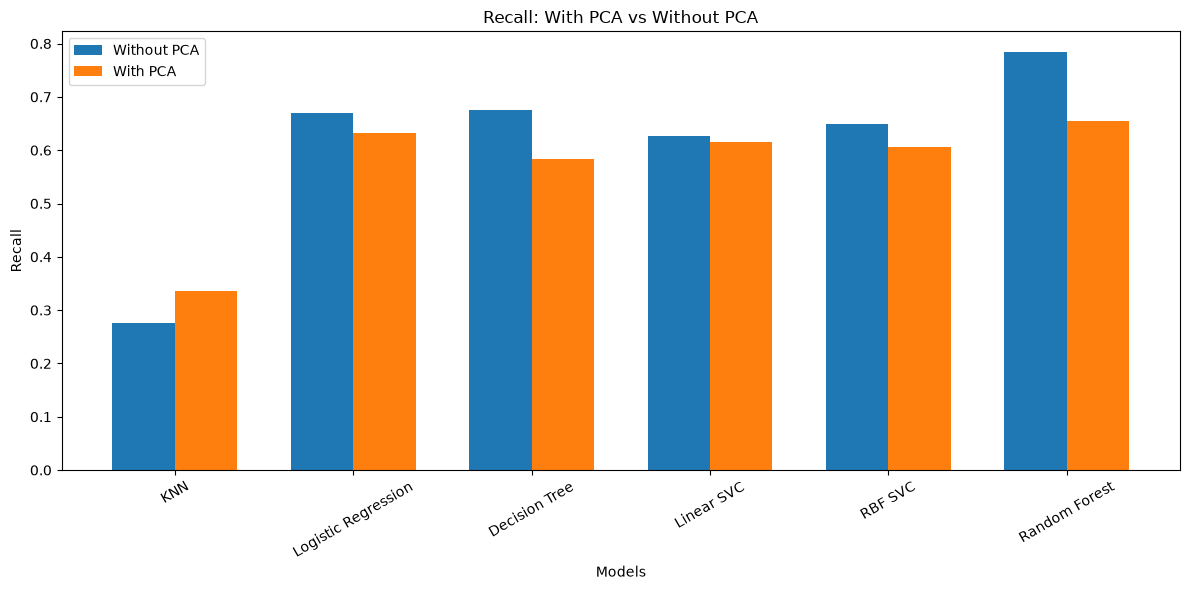

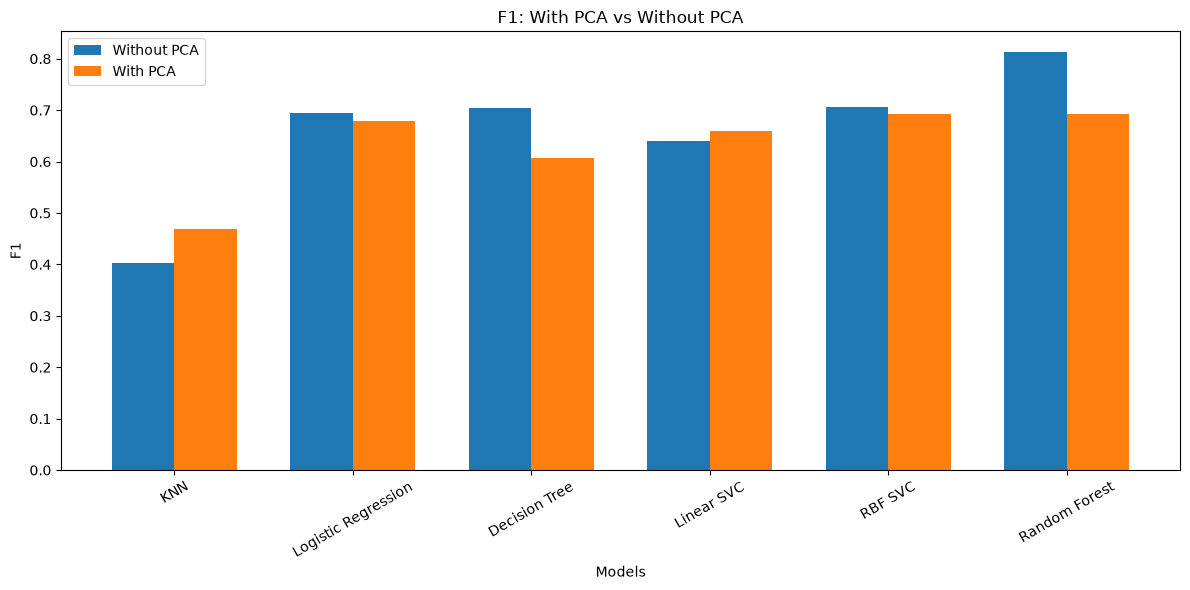

In [15]:
metrics = ["accuracy", "precision", "recall", "f1"]

for metric in metrics:
    plt.figure(figsize=(12, 6))

    x = np.arange(len(pca_comparison["model"]))
    width = 0.35

    plt.bar(
        x - width / 2,
        pca_comparison[f"{metric}_without_pca"],
        width,
        label="Without PCA"
    )

    plt.bar(
        x + width / 2,
        pca_comparison[f"{metric}_with_pca"],
        width,
        label="With PCA"
    )

    plt.xlabel("Models")
    plt.ylabel(metric.capitalize())
    plt.title(f"{metric.capitalize()}: With PCA vs Without PCA")
    plt.xticks(x, pca_comparison["model"], rotation=30)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"../Image/pca_{metric}_comparison.png",
        dpi=300
    )

    plt.show()

In [16]:
print(pca_comparison.columns.tolist())

['model', 'accuracy_without_pca', 'precision_without_pca', 'recall_without_pca', 'f1_without_pca', 'accuracy_with_pca', 'precision_with_pca', 'recall_with_pca', 'f1_with_pca']


In [17]:
pca_comparison = pca_comparison.rename(columns={
    "f1-score": "f1_without_pca"
})

In [18]:
pca_comparison.to_csv("pca_comparison_results.csv", index=False)

print("Final PCA comparison table saved successfully!")

Final PCA comparison table saved successfully!
